***1. Averaging filter (Filtre Moyenneur)***

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [3]:
img = cv2.imread('gray_disc.png', cv2.IMREAD_GRAYSCALE)

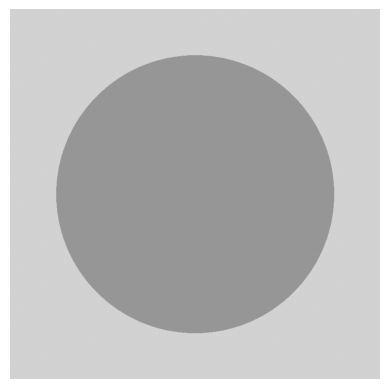

In [5]:
plt.imshow(img, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

In [7]:
h1 = np.ones((5, 5), np.float32) / 25
h2 = np.ones((11, 11), np.float32) / 121

# Appliquer les filtres avec filter2D
img_h1 = cv2.filter2D(img, -1, h1)
img_h2 = cv2.filter2D(img, -1, h2)

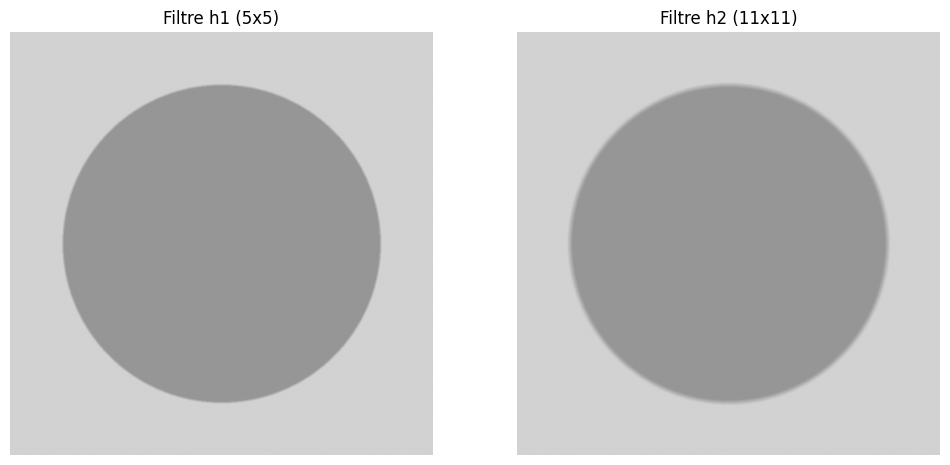

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))



plt.subplot(1, 2, 1)
plt.imshow(img_h1, cmap='gray', vmin=0, vmax=255) 
plt.title('Filtre h1 (5x5)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_h2, cmap='gray', vmin=0, vmax=255)
plt.title('Filtre h2 (11x11)')
plt.axis('off')

plt.show()

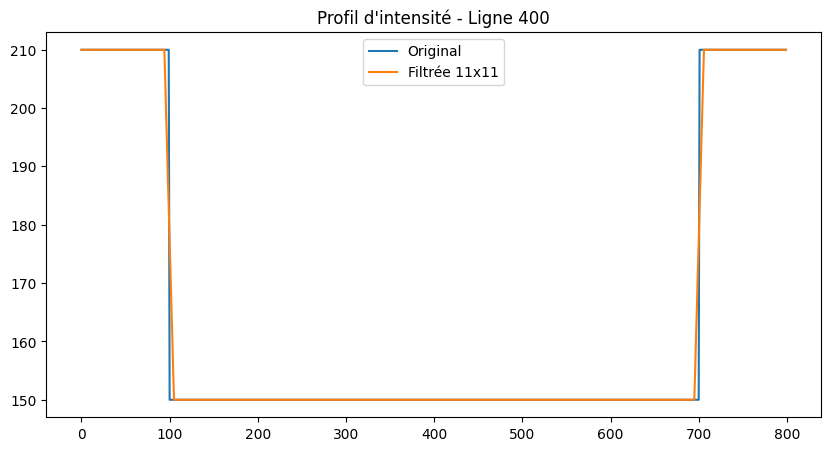

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(img[400, :], label='Original')
plt.plot(img_h2[400, :], label='Filtrée 11x11')
plt.title('Profil d\'intensité - Ligne 400')
plt.legend()
plt.show()

In [13]:
noised_img = cv2.imread('gray_disc_noised_gaussian.png', cv2.IMREAD_GRAYSCALE)

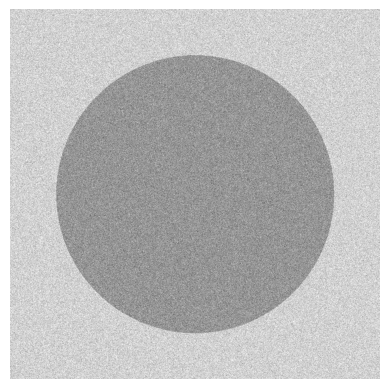

In [54]:
plt.imshow(noised_img, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.show()

In [15]:
noised_h1 = cv2.filter2D(noised_img, -1, h1)
noised_h2 = cv2.filter2D(noised_img, -1, h2)

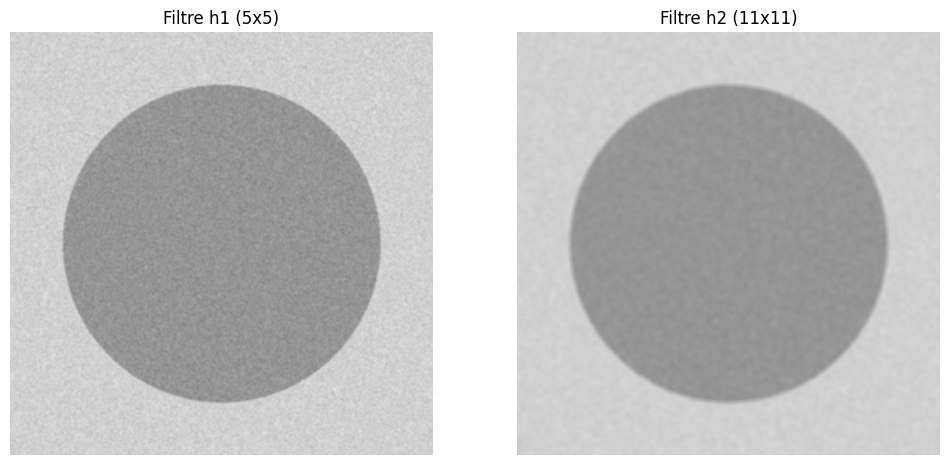

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))


plt.subplot(1, 2, 1)
plt.imshow(noised_h1, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(noised_h2, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.show()

***2. Median filter (Filtre Médian)***

In [20]:
noised_sp = cv2.imread('gray_disc_noised_s&p.png', cv2.IMREAD_GRAYSCALE)

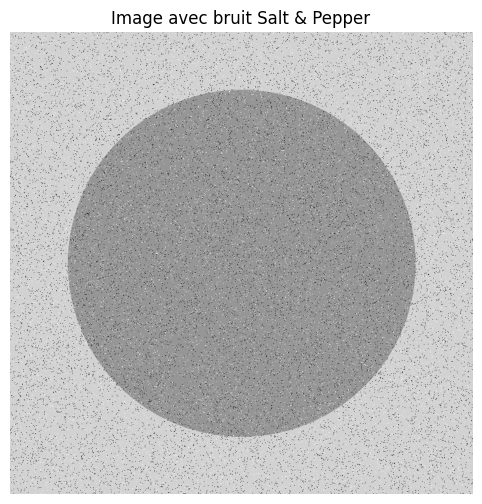

In [22]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

plt.imshow(noised_sp, cmap='gray')
plt.title('Image avec bruit Salt & Pepper')
plt.axis('off') 
plt.show()




In [24]:
img_sp_h2 = cv2.filter2D(noised_sp, -1, h2)

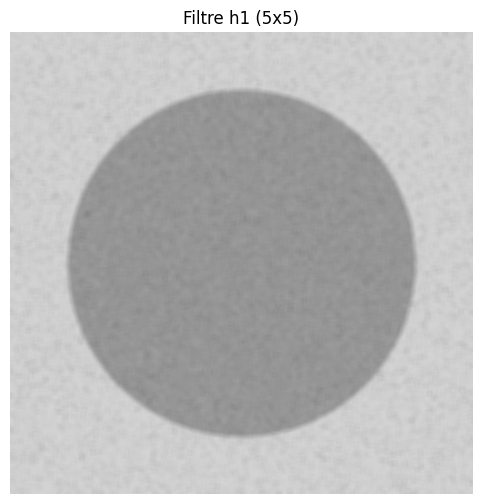

In [26]:
plt.figure(figsize=(12, 6))
plt.imshow(img_sp_h2 , cmap='gray', vmin=0, vmax=255) 
plt.title('Filtre h1 (5x5)')
plt.axis('off')
plt.show()

In [28]:

noised_img_gaussian = cv2.imread('gray_disc_noised_gaussian.png', cv2.IMREAD_GRAYSCALE)

if noised_img_gaussian is not None:
   
    denoised_gaussian_median = cv2.medianBlur(noised_img_gaussian, 9)

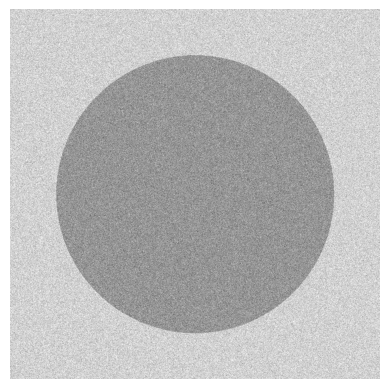

In [30]:
plt.imshow(noised_img_gaussian, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

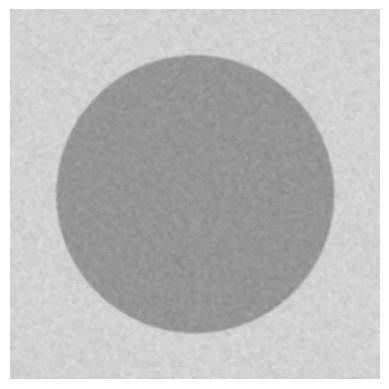

In [32]:
plt.imshow(denoised_gaussian_median, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

***3. Behind the scene (Implémentation manuelle)***

In [60]:
!pip install scikit-image

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
from skimage.util import random_noise
gauss_noise = random_noise(img, mode='gaussian')
gauss_noise = (gauss_noise * 255).astype(np.uint8)

# Bruit S&P
sp_noise = random_noise(img, mode='s&p', amount=0.05)
sp_noise = (sp_noise * 255).astype(np.uint8)

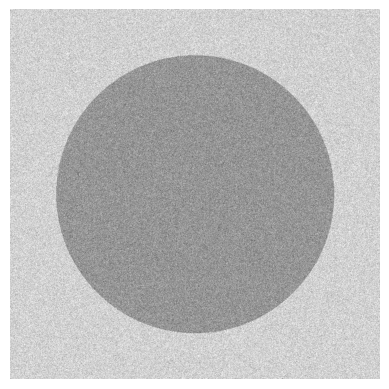

In [36]:
plt.imshow(gauss_noise , cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

In [40]:
def myConvolution(image, kernel):
    h_img, w_img = image.shape
    h_k, w_k = kernel.shape
    
    pad_h = h_k // 2
    pad_w = w_k // 2
    
    padded_img = cv2.copyMakeBorder(image, pad_h, pad_h, pad_w, pad_w, cv2.BORDER_REPLICATE)
    
    output = np.zeros((h_img, w_img), dtype=np.float32)
    
    for i in range(h_img):
        for j in range(w_img):
            roi = padded_img[i:i+h_k, j:j+w_k]
            
            output[i, j] = np.sum(roi * kernel)
            
    output = np.clip(output, 0, 255).astype(np.uint8)
    
    return output

h2 = np.ones((11, 11), np.float32) / 121

my_result = myConvolution(img, h2)

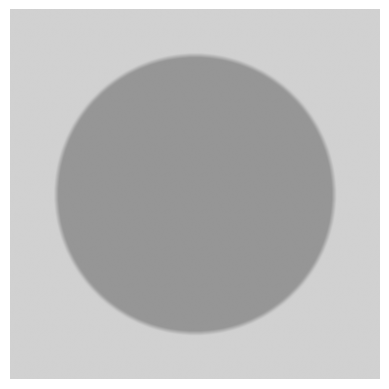

In [42]:
plt.imshow(my_result, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

In [48]:
def myMedianFilter(image, kernel_size):
    h_img, w_img = image.shape
    pad = kernel_size // 2
    
    padded_img = cv2.copyMakeBorder(image, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
    
    output = np.zeros((h_img, w_img), dtype=np.uint8)
    
    for i in range(h_img):
        for j in range(w_img):
            roi = padded_img[i:i+kernel_size, j:j+kernel_size]
            
            output[i, j] = np.median(roi)
            
    return output

if 'sp_noise' in locals():
    my_median_result = myMedianFilter(sp_noise, 9)
    print("Succès : Le filtrage médian personnalisé a été appliqué !")

Succès : Le filtrage médian personnalisé a été appliqué !


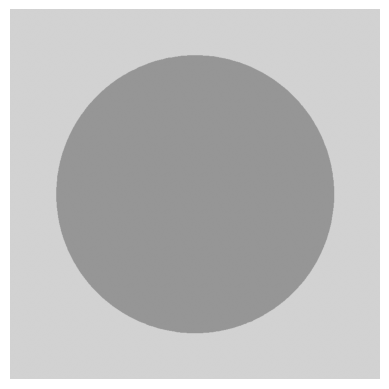

In [50]:
plt.imshow(my_median_result, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()